# M1: Baseline pencarian lintas modal
IF25-40304 · Kelompok 09

Atur `DIR` di sel 3 ke folder yang berisi `train.csv`, `val.csv`, dan `images/` (default `../bundle-mahasiswa`), lalu **Run All**.
Hasil mentah disimpan di `hasil/`, embedding di `cache/` (supaya M2 tidak mengulang pekerjaan mahal).

**Aturan leakage (instruksi M1):** hiperparameter dan contoh query hanya memakai `train.csv`. `val.csv` hanya dipakai untuk tabel hasil.

Atribusi data: SEA-VL Indonesian subset (KORIKA-AI/sea-vl_crowdsourcing_id), diturunkan dari SEACrowd/sea-vl_crowdsourcing, CC BY-SA 4.0. Cahyawijaya et al. (2025), *Crowdsource, Crawl, or Generate? Creating SEA-VL, a Multicultural Vision-Language Dataset for Southeast Asia*, ACL.

In [1]:
import os, re, json, time, random, platform, sys
import numpy as np, pandas as pd, torch
from PIL import Image
from IPython.display import display
import sentence_transformers
from sentence_transformers import SentenceTransformer

# ---------- PENGATURAN ----------
DIR = "../bundle-mahasiswa"  # folder berisi train.csv, val.csv, images/
SEED = 42
K_MAP = 10                   # K untuk mAP@K
IMG_MODEL = "sentence-transformers/clip-ViT-B-32"                  # encoder gambar + teks Inggris
TXT_MODEL = "sentence-transformers/clip-ViT-B-32-multilingual-v1"  # encoder teks Indonesia
BATCH_IMG, BATCH_TXT = 32, 64
# --------------------------------

OUT = os.path.abspath(".")   # cache/ dan hasil/ disimpan di folder notebook, bukan di folder bundel
os.chdir(DIR)
os.makedirs(f"{OUT}/cache", exist_ok=True); os.makedirs(f"{OUT}/hasil", exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

T_PATH = f"{OUT}/cache/waktu.json"
TIMES = json.load(open(T_PATH)) if os.path.exists(T_PATH) else {}

img_model = SentenceTransformer(IMG_MODEL, device="cpu")
txt_model = SentenceTransformer(TXT_MODEL, device="cpu")
print("model dimuat:", IMG_MODEL, "|", TXT_MODEL)

c:\Multimodal_Tubes\Multimodal-Machine-Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Multimodal_Tubes\Multimodal-Machine-Learning\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mrsan\.cache\huggingface\hub\models--sentence-transformers--clip-ViT-B-32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Pyt

model dimuat: sentence-transformers/clip-ViT-B-32 | sentence-transformers/clip-ViT-B-32-multilingual-v1


In [2]:
tr = pd.read_csv("train.csv"); va = pd.read_csv("val.csv")
print("train:", len(tr), "| val:", len(va))
for d in (tr, va):
    assert d["file"].map(os.path.exists).all(), "ada file gambar yang tidak ditemukan"

def enc_images(files, bs=BATCH_IMG):
    # dibaca per batch (bukan semua sekaligus) supaya memori aman
    out = []
    for i in range(0, len(files), bs):
        ims = [Image.open(f).convert("RGB") for f in files[i:i + bs]]
        out.append(img_model.encode(ims, batch_size=bs, normalize_embeddings=True))
        for im in ims: im.close()
    return np.concatenate(out)

def cached(name, fn):
    p = f"{OUT}/cache/{name}.npy"
    if os.path.exists(p): return np.load(p)
    t0 = time.time(); x = fn(); TIMES[name] = round(time.time() - t0, 1)
    np.save(p, x); json.dump(TIMES, open(T_PATH, "w"), indent=1)
    print(f"{name}: {x.shape} dalam {TIMES[name]} dtk"); return x

def embed_split(d, nama):
    E  = cached(f"{nama}_img",   lambda: enc_images(list(d["file"])))
    Ti = cached(f"{nama}_txt_id", lambda: txt_model.encode(list(d["caption_id"]), batch_size=BATCH_TXT, normalize_embeddings=True))
    Te = cached(f"{nama}_txt_en", lambda: img_model.encode(list(d["caption_en"]), batch_size=BATCH_TXT, normalize_embeddings=True))
    return E, Ti, Te

Ev, Tiv, Tev = embed_split(va, "val")

train: 2072 | val: 275
val_img: (275, 512) dalam 26.2 dtk
val_txt_id: (275, 512) dalam 9.7 dtk
val_txt_en: (275, 512) dalam 8.5 dtk


## Metrik
Satu jawaban benar per query (baris ke-i punya pasangan ke-i), sama dengan `truth = arange(N)` di ToR. Skor sama (tie) dihitung **pesimistik** (item yang skornya sama dianggap berada di depan), supaya caption duplikat tidak menggelembungkan hasil.

In [3]:
def ranks_of_truth(S, tol=1e-6):
    d = np.diag(S)[:, None]
    return (S >= d - tol).sum(1)           # peringkat jawaban benar (mulai dari 1), tie pesimistik

def n_tie(S, tol=1e-6):
    d = np.diag(S)[:, None]
    return int(((np.abs(S - d) <= tol).sum(1) > 1).sum())   # query yang punya item lain dengan skor sama

def metrics(S, ks=(1, 5, 10), K=K_MAP):
    r = ranks_of_truth(S)
    out = {f"R@{k}": float((r <= k).mean()) for k in ks}
    out[f"mAP@{K}"] = float(np.where(r <= K, 1.0 / r, 0.0).mean())   # 1 jawaban benar: AP = 1/peringkat
    return out, r

def boot_ci(hit, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(hit)
    m = np.array([hit[rng.integers(0, n, n)].mean() for _ in range(B)])
    return np.percentile(m, [2.5, 97.5])

ARAH = {
    "gambar → teks ID": lambda E, Ti, Te: E @ Ti.T,
    "gambar → teks EN": lambda E, Ti, Te: E @ Te.T,
    "teks ID → gambar": lambda E, Ti, Te: Ti @ E.T,
    "teks EN → gambar": lambda E, Ti, Te: Te @ E.T,
}

## Hasil pada split validasi (empat arah)

In [4]:
rows, RANK = [], {}
for nama, f in ARAH.items():
    S = f(Ev, Tiv, Tev)
    m, r = metrics(S); RANK[nama] = r
    lo, hi = boot_ci((r <= 1).astype(float))
    rows.append({"Arah": nama, **m, "R@1 CI95": f"[{lo:.3f}, {hi:.3f}]", "query dgn tie": n_tie(S)})
res = pd.DataFrame(rows).set_index("Arah")
N = len(va)
print(f"N gambar val = {N} | pembanding acak: R@1 = 1/N = {1/N:.4f}, R@5 = {5/N:.4f}, R@10 = {10/N:.4f} | mAP@{K_MAP} acak ≈ {sum(1/i for i in range(1, K_MAP+1))/N:.4f}")
res.round(4).to_csv(f"{OUT}/hasil/val_empat_arah.csv")
res.round(4)

N gambar val = 275 | pembanding acak: R@1 = 1/N = 0.0036, R@5 = 0.0182, R@10 = 0.0364 | mAP@10 acak ≈ 0.0107


,R@1,R@5,R@10,mAP@10,R@1 CI95,query dgn tie
Arah,,,,,,
gambar → teks ID,0.2145,0.3782,0.5055,0.2931,"[0.167, 0.265]",2
gambar → teks EN,0.4400,0.7127,0.8327,0.5561,"[0.378, 0.502]",2
teks ID → gambar,0.1964,0.4145,0.5055,0.2834,"[0.149, 0.244]",0
teks EN → gambar,0.3782,0.6764,0.7709,0.5057,"[0.324, 0.436]",0


## Language gap (ID vs EN)

In [5]:
g = {}
for sisi, (a, b) in {"gambar→teks": ("gambar → teks EN", "gambar → teks ID"),
                     "teks→gambar": ("teks EN → gambar", "teks ID → gambar")}.items():
    ren, rid = res.loc[a, "R@1"], res.loc[b, "R@1"]
    g[sisi] = dict(R1_EN=ren, R1_ID=rid, gap=ren - rid, gap_rel=(ren - rid) / ren * 100,
                   mAP_gap=res.loc[a, f"mAP@{K_MAP}"] - res.loc[b, f"mAP@{K_MAP}"])
gap = pd.DataFrame(g).T
display(gap.round(4))
# kategori mana yang paling menanggung gap (teks→gambar, R@1)
hit_en = (RANK["teks EN → gambar"] <= 1); hit_id = (RANK["teks ID → gambar"] <= 1)
per_kat = pd.DataFrame({"kategori": va["category"], "EN": hit_en, "ID": hit_id}).groupby("kategori").agg(n=("EN", "size"), R1_EN=("EN", "mean"), R1_ID=("ID", "mean"))
per_kat["gap"] = per_kat["R1_EN"] - per_kat["R1_ID"]
print("Catatan: kategori dengan n < 10 tidak stabil, jangan dijadikan klaim.")
per_kat.sort_values("n", ascending=False).round(3)

,R1_EN,R1_ID,gap,gap_rel,mAP_gap
gambar→teks,0.4400,0.2145,0.2255,51.2397,0.2630
teks→gambar,0.3782,0.1964,0.1818,48.0769,0.2223


Catatan: kategori dengan n < 10 tidak stabil, jangan dijadikan klaim.


,n,R1_EN,R1_ID,gap
kategori,,,,
kuliner,106,0.264,0.047,0.217
lain-lain,52,0.423,0.192,0.231
tarian,32,0.312,0.156,0.156
arsitektur/bangunan,24,0.458,0.250,0.208
wayang/seni,18,0.611,0.444,0.167
tempat/alam,17,0.647,0.471,0.176
pakaian/tekstil,12,0.250,0.250,0.000
flora/fauna,8,0.625,0.625,0.000
transportasi,4,0.750,0.750,0.000


## Sepuluh contoh query Indonesia (hanya dari `train.csv`)
Instruksi M1 melarang memilih contoh dengan melihat `val.csv`, jadi contoh diambil acak (seed tetap) dari train, dengan galeri = seluruh gambar train. Contoh gagal ditampilkan apa adanya.

In [6]:
Etr, Titr, Tetr = embed_split(tr, "train")
S_tr = Titr @ Etr.T                                   # query teks ID -> semua gambar train
top = np.argsort(-S_tr, axis=1)[:, :3]
benar = (np.argmax(S_tr, axis=1) == np.arange(len(tr)))
print(f"[info] R@1 teks ID → gambar pada galeri train ({len(tr)} gambar): {benar.mean():.3f}")

rng = np.random.default_rng(SEED)
idx = list(rng.choice(len(tr), 10, replace=False))
gagal = [i for i in idx if not benar[i]]
if len(gagal) < 2:                                    # pastikan >= 2 contoh gagal (diambil acak dari kegagalan lain)
    extra = [i for i in rng.permutation(np.where(~benar)[0]) if i not in idx][: 2 - len(gagal)]
    sukses = [i for i in idx if benar[i]]
    for e, s in zip(extra, sukses[::-1]): idx[idx.index(s)] = e
    print("[info] sampel acak <2 gagal; diganti dengan kegagalan acak:", extra)

norm = lambda s: re.sub(r"\W+", " ", str(s).lower()).strip()
cap = tr["caption_id"].tolist()
rows = []
for n, i in enumerate(idx, 1):
    t3 = top[i]
    rows.append({"#": n, "Query (ID)": cap[i],
                 "Hasil teratas (3)": " | ".join(f"{cap[j]}{' ✔' if j == i else ''}" for j in t3),
                 "Benar?": "ya" if benar[i] else "tidak",
                 "Catatan": "caption identik dengan gambar lain" if any(norm(cap[j]) == norm(cap[i]) and j != i for j in t3) else ""})
contoh = pd.DataFrame(rows)
contoh.to_csv(f"{OUT}/hasil/contoh_query_train.csv", index=False)
pd.set_option("display.max_colwidth", 140)
contoh

train_img: (2072, 512) dalam 245.7 dtk
train_txt_id: (2072, 512) dalam 41.2 dtk
train_txt_en: (2072, 512) dalam 44.4 dtk
[info] R@1 teks ID → gambar pada galeri train (2072 gambar): 0.068


,#,Query (ID),Hasil teratas (3),Benar?,Catatan
0,1,"Pose 2 penari gambyong ayun-ayun dengan kemben berwarna merah, jarik batik, dan selendang kuning.",Potret empat penari Merak yang siap untuk berlomba. | 2 penari Gambyong Pareanom dalam posisi mendak sambil memegang sampurnya. | Pose y...,tidak,
1,2,"Sate kelapa, atau dikenal juga sebagai sate klopo, adalah salah satu variasi unik dari hidangan sate yang populer di Indonesia.","Potongan jengkol yang dimasak dengan bumbu rendang, disajikan di atas daun pisang. | Serabi, jajanan yang terbuat dari tepung beras, san...",tidak,
2,3,Posisi mendhak yang dilakukan oleh tiga penari Gambyong Pareanom.,Potret empat penari Merak yang siap untuk berlomba. | Penampilan dari para penari Beksan Jemparing di sebuah pendopo. | Foto yang memper...,tidak,
3,4,Porsi babi guling lengkap dengan nasi dan kerupuk kulit babi yang renyah,"Ketoprak dengan saus kacang khas Betawi | Nasi, bihun goreng, orek tempe, telur goreng, dan kerupuk disajikan untuk sarapan | Makan Gude...",tidak,
4,5,"Jajanan pasar yang terdiri dari lemper (bungkusan warna coklat gelap), nagasari (coklat muda), ketan putih (bungkusan hijau), puding lab...","Dodol Garut Zebra, jajanan khas Garut, dipajang di toko oleh-oleh | Kumpulan jajanan pasar yang terdiri atas berbagai macam makanan asis...",tidak,
5,6,Sate ayam dengan bumbu kacang dan lontong.,"Lontong Kikil Surabaya | Dua porsi Mie Bangka, masing-masing dengan sup beningmya | Ayam Geprek khas jogja dengan cabe di ata ayam.",tidak,
6,7,Gereja Blenduk (dibangun pada tahun 1753) di Semarang,Masjid Gedhe Kauman adalah masjid tertua di Yogyakarta yang terletak di sebelah barat Alun-Alun Utara Keraton Yogyakarta. | Gereja Blend...,tidak,
7,8,Para penari wanita dalam sebuah pementasan tari yang bernuansa budaya Jawa gaya Yogyakarta.,Gerakan Seblak Sampur yang dilakukan oleh penari Beksan Jemparing. | Tiga penari Remo yang melakukan posisi malangkrik dengan busana ber...,tidak,
8,9,Dandanan karakter kerbau dan sapi dalam sebuah sendratari.,"Patung petani dan sapi, diambil di museum | Gambar properti kuda lumping yang sering digunakan dalam pementasan tari Jathilan. | Relief ...",tidak,
9,10,"Komodo, spesies biawak besar yang berasal dari Pulau Komodo",Tradisi pare gede atau mengangkut padi dari sawah olot yang telah dipanen oleh masyarakat. | Jenang Klobot adalah jajanan tradisional kh...,tidak,


#1 [GAGAL] query: Pose 2 penari gambyong ayun-ayun dengan kemben berwarna merah, jarik batik, dan selendang kuning.  (kiri: gambar asli, lalu top-3)


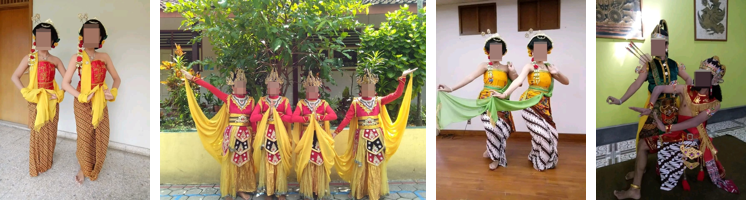

#2 [GAGAL] query: Sate kelapa, atau dikenal juga sebagai sate klopo, adalah salah satu variasi unik dari hidangan sate yang populer di Indonesia.  (kiri: gambar asli, lalu top-3)


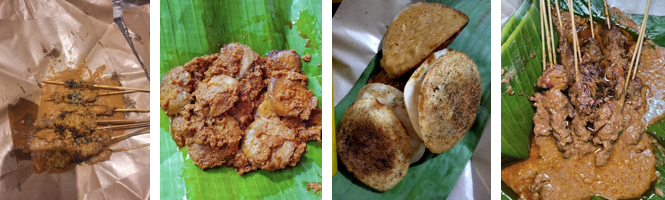

#3 [GAGAL] query: Posisi mendhak yang dilakukan oleh tiga penari Gambyong Pareanom.  (kiri: gambar asli, lalu top-3)


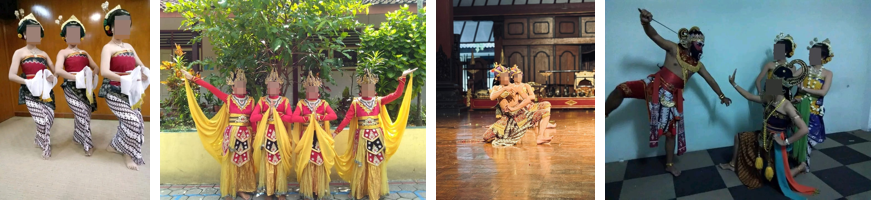

#4 [GAGAL] query: Porsi babi guling lengkap dengan nasi dan kerupuk kulit babi yang renyah  (kiri: gambar asli, lalu top-3)


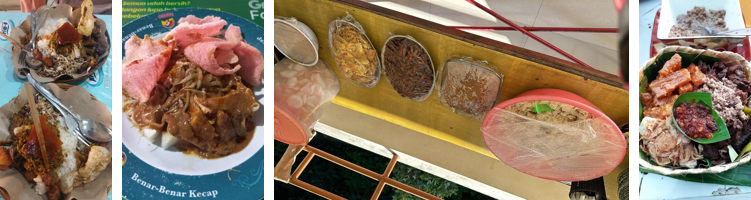

#5 [GAGAL] query: Jajanan pasar yang terdiri dari lemper (bungkusan warna coklat gelap), nagasari (coklat muda), ketan putih (bungkusan hijau), puding labu kuning (warna putih), dan kue kukus (warna merah muda).  (kiri: gambar asli, lalu top-3)


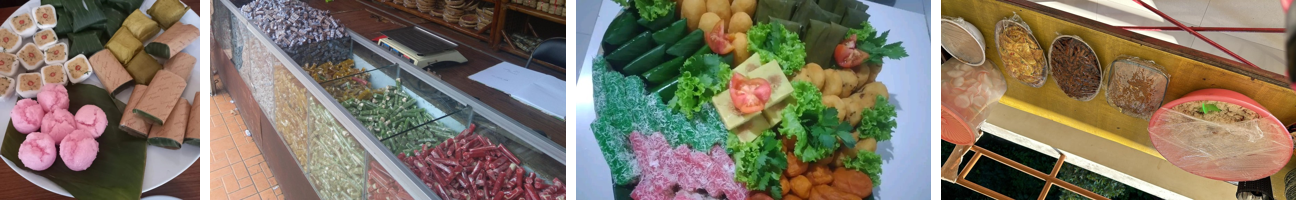

#6 [GAGAL] query: Sate ayam dengan bumbu kacang dan lontong.  (kiri: gambar asli, lalu top-3)


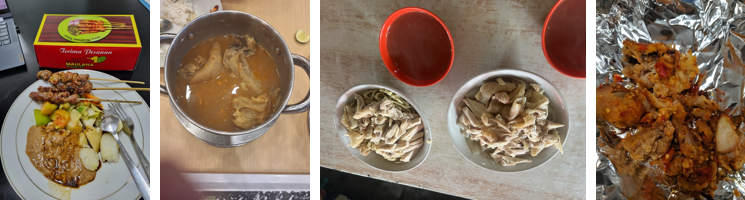

#7 [GAGAL] query: Gereja Blenduk (dibangun pada tahun 1753) di Semarang  (kiri: gambar asli, lalu top-3)


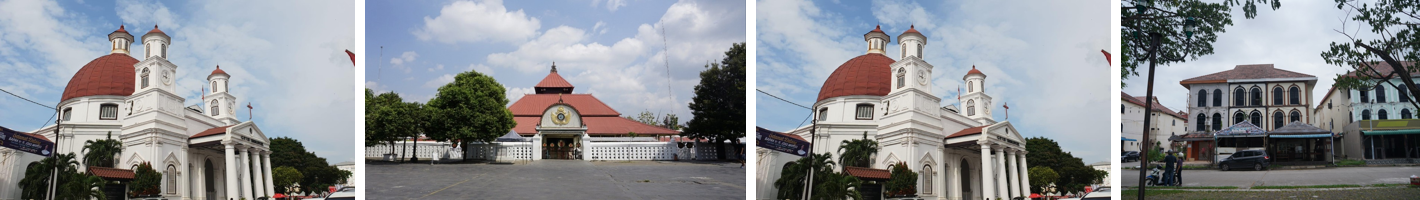

#8 [GAGAL] query: Para penari wanita dalam sebuah pementasan tari yang bernuansa budaya Jawa gaya Yogyakarta.  (kiri: gambar asli, lalu top-3)


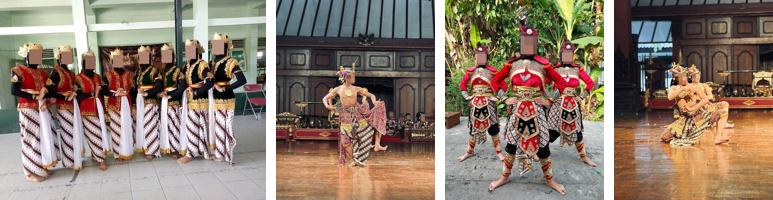

#9 [GAGAL] query: Dandanan karakter kerbau dan sapi dalam sebuah sendratari.  (kiri: gambar asli, lalu top-3)


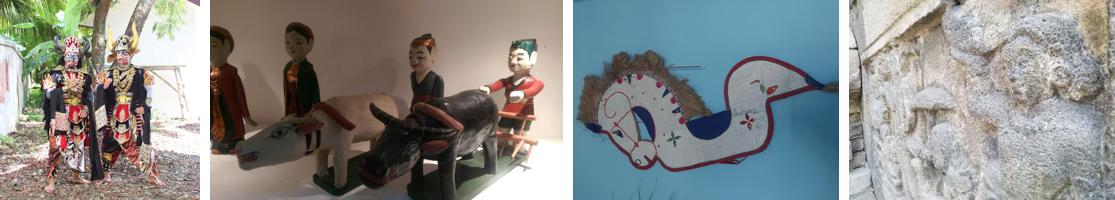

#10 [GAGAL] query: Komodo, spesies biawak besar yang berasal dari Pulau Komodo  (kiri: gambar asli, lalu top-3)


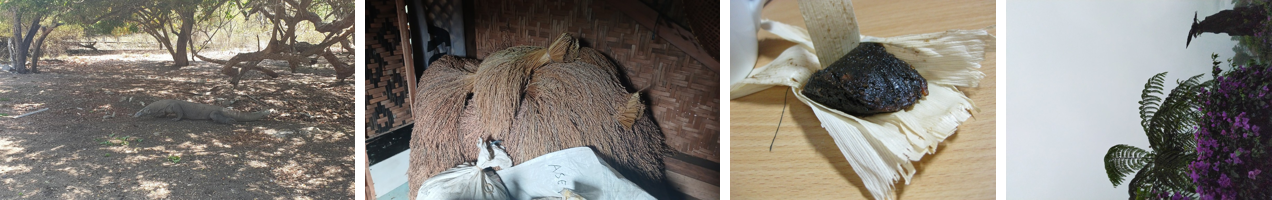

In [7]:
def tile(paths, h=200):
    ims = []
    for p in paths:
        im = Image.open(p).convert("RGB"); ims.append(im.resize((int(im.width * h / im.height), h)))
    W = sum(i.width for i in ims) + 10 * (len(ims) - 1)
    c = Image.new("RGB", (W, h), "white"); x = 0
    for im in ims: c.paste(im, (x, 0)); x += im.width + 10
    return c

for n, i in enumerate(idx, 1):
    print(f"#{n} [{'BENAR' if benar[i] else 'GAGAL'}] query: {cap[i]}  (kiri: gambar asli, lalu top-3)")
    display(tile([tr['file'][i]] + [tr['file'][j] for j in top[i]]))

## Ringkasan, perangkat, dan waktu jalan

In [8]:
print("Perangkat   :", platform.platform(), "|", platform.processor() or "CPU", "|", os.cpu_count(), "core | GPU:", torch.cuda.is_available())
print("Perangkat lunak: Python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| sentence-transformers", sentence_transformers.__version__)
print("Seed", SEED, "| batch gambar", BATCH_IMG, "| batch teks", BATCH_TXT)
print("Waktu embedding (detik, cache kosong):", TIMES, "| total:", round(sum(TIMES.values()), 1))

print("\n--- TABEL UNTUK LAPORAN (val, seed", SEED, ") ---")
print("| Arah | R@1 | R@5 | R@10 | mAP@%d |" % K_MAP); print("|---|---|---|---|---|")
for a, r in res.iterrows(): print(f"| {a} | {r['R@1']:.3f} | {r['R@5']:.3f} | {r['R@10']:.3f} | {r[f'mAP@{K_MAP}']:.3f} |")

gt, gi = gap.loc["gambar→teks"], gap.loc["teks→gambar"]
print(f"\nGap R@1 (EN−ID): gambar→teks {gt['gap']:.3f} ({gt['gap_rel']:.1f}% relatif), teks→gambar {gi['gap']:.3f} ({gi['gap_rel']:.1f}% relatif).")
print(f"Pembanding acak R@1 = 1/{N} = {1/N:.4f}.")

Perangkat   : Windows-11-10.0.26300-SP0 | Intel64 Family 6 Model 154 Stepping 4, GenuineIntel | 12 core | GPU: False
Perangkat lunak: Python 3.12.10 | numpy 2.5.4 | torch 2.15.0+cpu | sentence-transformers 6.3.0
Seed 42 | batch gambar 32 | batch teks 64
Waktu embedding (detik, cache kosong): {'val_img': 26.2, 'val_txt_id': 9.7, 'val_txt_en': 8.5, 'train_img': 245.7, 'train_txt_id': 41.2, 'train_txt_en': 44.4} | total: 375.7

--- TABEL UNTUK LAPORAN (val, seed 42 ) ---
| Arah | R@1 | R@5 | R@10 | mAP@10 |
|---|---|---|---|---|
| gambar → teks ID | 0.215 | 0.378 | 0.505 | 0.293 |
| gambar → teks EN | 0.440 | 0.713 | 0.833 | 0.556 |
| teks ID → gambar | 0.196 | 0.415 | 0.505 | 0.283 |
| teks EN → gambar | 0.378 | 0.676 | 0.771 | 0.506 |

Gap R@1 (EN−ID): gambar→teks 0.225 (51.2% relatif), teks→gambar 0.182 (48.1% relatif).
Pembanding acak R@1 = 1/275 = 0.0036.
